In [1]:
!pip install pandas numpy matplotlib seaborn plotly scikit-learn wordcloud

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import re
import warnings
warnings.filterwarnings("ignore")

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score

from google.colab import files

In [3]:
uploaded = files.upload()

Saving social_media_comments.csv to social_media_comments.csv
Saving social_media_posts.csv to social_media_posts.csv


In [4]:
posts = pd.read_csv("social_media_posts.csv")
comments = pd.read_csv("social_media_comments.csv")

print("Posts:", posts.shape)
print("Comments:", comments.shape)

display(posts.head())
display(comments.head())

Posts: (500, 15)
Comments: (3716, 10)


,post_id,brand,platform,campaign,content_type,product_category,likes,comments_count,shares,views,days_since_post,post_date,city_focus,source_url,data_source
0,P0001,Khaadi,Facebook,New Arrivals,Product Photo,Women's Lawn Suit,204,23,17,2444.0,26,2026-06-03,Faisalabad,NaN,Simulated
1,P0002,Gul Ahmed,TikTok,12.12 Winter Edit,Styling Video,Women's Lawn Suit,1475,78,192,25324.0,17,2026-05-14,Multan,NaN,Simulated
2,P0003,Gul Ahmed,Facebook,Eid Collection,Product Photo,Women's Lawn Suit,258,48,9,NaN,30,2026-06-13,Sialkot,NaN,Simulated
3,P0004,Sapphire,TikTok,Ramadan Collection,Product Photo,Ready-to-Wear,1031,220,88,31445.0,3,2026-05-21,Multan,NaN,Simulated
4,P0005,Sapphire,Instagram,Ramadan Collection,Sale Announcement,Unstitched Suit,1006,84,45,13730.0,22,2026-03-13,Multan,NaN,Simulated


,comment_id,post_id,comment_text,language_type,reference_topic,reference_sentiment,reference_purchase_intent,collection_date,source_url,data_source
0,C000001,P0001,Order abhi tak receive nahi hua.,English,Delivery concern,Neutral,Low,2026-11-15,NaN,Simulated
1,C000002,P0001,Please update my order.,English,Delivery concern,Negative,Low,2026-11-15,NaN,Simulated
2,C000003,P0001,Rate please,English,Price inquiry,Neutral,Possible,2026-11-15,NaN,Simulated
3,C000004,P0001,"My order is delayed, please help.",English,Delivery concern,Neutral,Low,2026-11-15,NaN,Simulated
4,C000005,P0001,What is the price of this article?,English,Price inquiry,Neutral,Possible,2026-11-15,NaN,Simulated


In [5]:
print("POST DATA")
print(posts.isnull().sum())

print("\nCOMMENT DATA")
print(comments.isnull().sum())

print("\nDuplicate posts:", posts.duplicated("post_id").sum())
print("Duplicate comments:", comments.duplicated("comment_id").sum())

POST DATA
post_id               0
brand                 0
platform              0
campaign              0
content_type          0
product_category      0
likes                 0
comments_count        0
shares                0
views                65
days_since_post       0
post_date             0
city_focus            0
source_url          500
data_source           0
dtype: int64

COMMENT DATA
comment_id                      0
post_id                         0
comment_text                    0
language_type                   0
reference_topic                 0
reference_sentiment             0
reference_purchase_intent       0
collection_date                 0
source_url                   3716
data_source                     0
dtype: int64

Duplicate posts: 0
Duplicate comments: 0


In [6]:
unmatched = comments[
    ~comments["post_id"].isin(posts["post_id"])
]

print("Comments without matching posts:", len(unmatched))

Comments without matching posts: 0


In [7]:
print(posts["platform"].value_counts())
print(posts["content_type"].value_counts())

print(comments["language_type"].value_counts())

platform
Instagram    241
Facebook     151
TikTok       108
Name: count, dtype: int64
content_type
Reel                 138
Product Photo        103
Styling Video         85
Sale Announcement     68
Influencer Post       63
Carousel              43
Name: count, dtype: int64
language_type
English       2221
Roman Urdu    1495
Name: count, dtype: int64


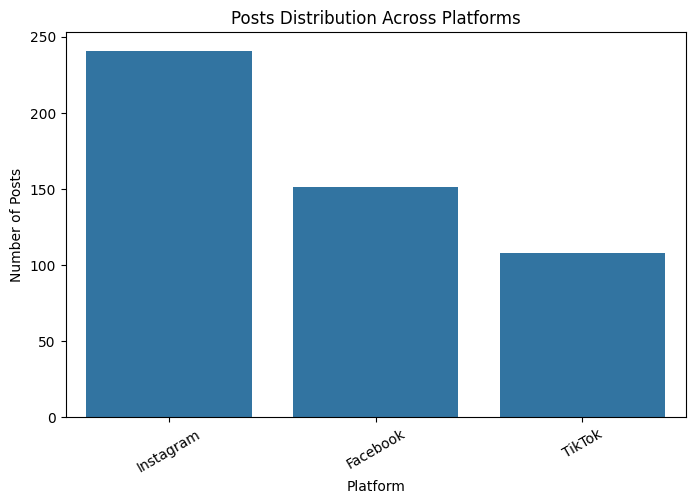

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=posts,
    x="platform",
    order=posts["platform"].value_counts().index
)

plt.title("Posts Distribution Across Platforms")
plt.xlabel("Platform")
plt.ylabel("Number of Posts")
plt.xticks(rotation=30)
plt.show()

In [9]:
content_summary = posts.groupby("content_type").agg(
    total_posts=("post_id", "count"),
    total_likes=("likes", "sum"),
    total_comments=("comments_count", "sum")
).reset_index()

display(content_summary)

,content_type,total_posts,total_likes,total_comments
0,Carousel,43,47695,5880
1,Influencer Post,63,93950,13967
2,Product Photo,103,73142,10018
3,Reel,138,265977,36101
4,Sale Announcement,68,101988,12450
5,Styling Video,85,135407,17505


In [10]:
for col in ["likes", "comments_count", "shares", "views"]:
    posts[col] = pd.to_numeric(posts[col], errors="coerce")

posts["total_engagement"] = (
    posts["likes"].fillna(0)
    + posts["comments_count"].fillna(0)
    + posts["shares"].fillna(0)
)

In [11]:
posts["engagement_rate"] = np.where(
    posts["views"] > 0,
    (posts["total_engagement"] / posts["views"]) * 100,
    np.nan
)

In [12]:
content_performance = posts.groupby("content_type").agg(
    average_likes=("likes", "mean"),
    average_comments=("comments_count", "mean"),
    average_engagement=("total_engagement", "mean"),
    average_engagement_rate=("engagement_rate", "mean")
).reset_index()

display(content_performance)

,content_type,average_likes,average_comments,average_engagement,average_engagement_rate
0,Carousel,1109.186047,136.744186,1341.116279,6.793193
1,Influencer Post,1491.269841,221.698413,1845.349206,6.525140
2,Product Photo,710.116505,97.262136,882.601942,6.582775
3,Reel,1927.369565,261.601449,2379.072464,6.748933
4,Sale Announcement,1499.823529,183.088235,1801.308824,7.068781
5,Styling Video,1593.023529,205.941176,1939.400000,6.729533


In [13]:
fig = px.bar(
    content_performance,
    x="content_type",
    y="average_engagement",
    title="Average Engagement by Content Type",
    color="content_type"
)

fig.show()

In [14]:
comments = comments.dropna(subset=["comment_text"]).copy()

def clean_text(text):

    text = str(text).lower()

    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#", "", text)
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text)

    return text.strip()

comments["cleaned_comment"] = (
    comments["comment_text"].apply(clean_text)
)

comments = comments[
    comments["cleaned_comment"].str.len() > 1
].copy()

display(comments[[
    "comment_text",
    "cleaned_comment"
]].head(10))

,comment_text,cleaned_comment
0,Order abhi tak receive nahi hua.,order abhi tak receive nahi hua
1,Please update my order.,please update my order
2,Rate please,rate please
3,"My order is delayed, please help.",my order is delayed please help
4,What is the price of this article?,what is the price of this article
5,Please resolve my complaint.,please resolve my complaint
6,Can I place an order?,can i place an order
7,How long does delivery take?,how long does delivery take
8,Poor response from customer support.,poor response from customer support
9,Sale kab start hogi?,sale kab start hogi


In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack

word_vectorizer = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    max_features=10000,
    min_df=2
)

char_vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(2, 5),
    max_features=10000,
    min_df=2
)

X_word = word_vectorizer.fit_transform(
    comments["cleaned_comment"]
)

X_char = char_vectorizer.fit_transform(
    comments["cleaned_comment"]
)

X = hstack([X_word, X_char])

print("TF-IDF matrix:", X.shape)

TF-IDF matrix: (3716, 3384)


In [16]:
kmeans = KMeans(
    n_clusters=7,
    random_state=42,
    n_init=10
)

comments["cluster"] = kmeans.fit_predict(X)

display(
    comments[["comment_text", "cluster"]].head(20)
)

,comment_text,cluster
0,Order abhi tak receive nahi hua.,3
1,Please update my order.,3
2,Rate please,1
3,"My order is delayed, please help.",3
4,What is the price of this article?,4
5,Please resolve my complaint.,3
6,Can I place an order?,3
7,How long does delivery take?,3
8,Poor response from customer support.,3
9,Sale kab start hogi?,4


In [17]:
cluster_counts = comments["cluster"].value_counts().sort_index()

print(cluster_counts)

cluster
0    113
1    226
2    533
3    898
4    715
5    564
6    667
Name: count, dtype: int64


In [18]:
sample_size = min(1000, X.shape[0])

X_sample = X[
    np.random.RandomState(42)
    .choice(X.shape[0], sample_size, replace=False)
]

labels_sample = comments["cluster"].iloc[
    np.random.RandomState(42)
    .choice(X.shape[0], sample_size, replace=False)
]

score = silhouette_score(X_sample, labels_sample)

print("Silhouette Score:", score)

Silhouette Score: 0.12575625758678935


In [19]:
rng = np.random.RandomState(42)

indices = rng.choice(
    X.shape[0],
    min(1000, X.shape[0]),
    replace=False
)

score = silhouette_score(
    X[indices],
    comments["cluster"].iloc[indices]
)

print("Silhouette Score:", score)

Silhouette Score: 0.12575625758678935


In [20]:
terms = word_vectorizer.get_feature_names_out()

for cluster_id in sorted(comments["cluster"].unique()):

    print("\nCLUSTER:", cluster_id)

    cluster_indices = np.where(
        comments["cluster"].values == cluster_id
    )[0]

    cluster_center = kmeans.cluster_centers_[cluster_id]

    top_terms = cluster_center[:len(terms)].argsort()[-10:][::-1]

    print("Top words:")

    for index in top_terms:
        print(terms[index])

    print("\nSample comments:")

    print(
        comments.loc[
            comments["cluster"] == cluster_id,
            "comment_text"
        ].head(8).to_string(index=False)
    )


CLUSTER: 0
Top words:
to
to buy
buy
buy this
want to
want
this suit
suit
this
one is

Sample comments:
No one is replying to my messages.
          I want to buy this suit.
          I want to buy this suit.
No one is replying to my messages.
          I want to buy this suit.
          I want to buy this suit.
       Such an elegant collection.
          I want to buy this suit.

CLUSTER: 1
Top words:
rate
rate please
inbox
kar dein
kar
dein
inbox kar
rate inbox
iska rate
iska

Sample comments:
                    Rate please
Inbox me details send kar dein.
                    Rate please
                    Rate please
      Iska rate inbox kar dein.
      Iska rate inbox kar dein.
      Iska rate inbox kar dein.
      Iska rate inbox kar dein.

CLUSTER: 2
Top words:
available
size
in
available hai
available in
size available
discount available
hai
lahore
in lahore

Sample comments:
              Available in Lahore?
           Large size mil jaye ga?
       Iska XL size available h

In [21]:
cluster_labels = {
    0: "Price Inquiries",
    1: "Discount Seekers",
    2: "Fabric and Quality",
    3: "Sizing and Availability",
    4: "Delivery Concerns",
    5: "Purchase Interest",
    6: "Product Appreciation"
}

comments["cluster_label"] = comments["cluster"].map(
    cluster_labels
)

In [22]:
cluster_summary = comments.groupby(
    "cluster_label"
).agg(
    total_comments=("comment_id", "count"),
    unique_posts=("post_id", "nunique")
).reset_index()

cluster_summary = cluster_summary.sort_values(
    "total_comments",
    ascending=False
)

display(cluster_summary)

,cluster_label,total_comments,unique_posts
6,Sizing and Availability,898,420
0,Delivery Concerns,715,391
4,Product Appreciation,667,382
5,Purchase Interest,564,337
2,Fabric and Quality,533,330
1,Discount Seekers,226,178
3,Price Inquiries,113,95


In [23]:
features = [
    "likes",
    "comments_count",
    "shares",
    "views",
    "total_engagement"
]

X_posts = posts[features].copy()

X_posts = np.log1p(X_posts.clip(lower=0))

imputer = SimpleImputer(strategy="median")

X_posts = imputer.fit_transform(X_posts)

scaler = StandardScaler()

X_posts = scaler.fit_transform(X_posts)

In [24]:
iso = IsolationForest(
    contamination=0.05,
    random_state=42
)

predictions = iso.fit_predict(X_posts)

posts["anomaly_flag"] = np.where(
    predictions == -1,
    "Unusual",
    "Normal"
)

display(
    posts[[
        "post_id",
        "platform",
        "content_type",
        "total_engagement",
        "anomaly_flag"
    ]].head(20)
)

,post_id,platform,content_type,total_engagement,anomaly_flag
0,P0001,Facebook,Product Photo,244,Unusual
1,P0002,TikTok,Styling Video,1745,Normal
2,P0003,Facebook,Product Photo,315,Normal
3,P0004,TikTok,Product Photo,1339,Normal
4,P0005,Instagram,Sale Announcement,1135,Normal
5,P0006,Instagram,Reel,1317,Normal
6,P0007,Instagram,Styling Video,1427,Normal
7,P0008,Instagram,Reel,690,Normal
8,P0009,Facebook,Sale Announcement,612,Normal
9,P0010,Facebook,Reel,1118,Normal


In [25]:
fig = px.scatter(
    posts,
    x="likes",
    y="comments_count",
    color="anomaly_flag",
    hover_data=["post_id", "platform", "content_type"],
    title="Unusual Social Media Engagement Patterns"
)

fig.show()

In [26]:
merged = comments.merge(
    posts[[
        "post_id",
        "brand",
        "platform",
        "campaign",
        "content_type"
    ]],
    on="post_id",
    how="left"
)

In [27]:
platform_clusters = pd.crosstab(
    merged["platform"],
    merged["cluster_label"]
)

display(platform_clusters)

cluster_label,Delivery Concerns,Discount Seekers,Fabric and Quality,Price Inquiries,Product Appreciation,Purchase Interest,Sizing and Availability
platform,,,,,,,
Facebook,218,64,149,33,191,178,279
Instagram,355,117,270,56,326,251,427
TikTok,142,45,114,24,150,135,192


In [28]:
fig = px.imshow(
    platform_clusters,
    text_auto=True,
    aspect="auto",
    title="Audience Needs Across Social Media Platforms"
)

fig.show()

In [29]:
content_clusters = pd.crosstab(
    merged["content_type"],
    merged["cluster_label"]
)

display(content_clusters)

cluster_label,Delivery Concerns,Discount Seekers,Fabric and Quality,Price Inquiries,Product Appreciation,Purchase Interest,Sizing and Availability
content_type,,,,,,,
Carousel,59,15,49,8,61,42,84
Influencer Post,95,27,61,22,75,83,117
Product Photo,150,49,117,21,122,100,193
Reel,212,58,134,27,212,133,248
Sale Announcement,81,32,70,17,83,105,118
Styling Video,118,45,102,18,114,101,138


In [30]:
recommendations = {
    "Price Inquiries":
        "Display product prices clearly in captions and posts.",

    "Discount Seekers":
        "Test limited-time promotions and bundle offers.",

    "Fabric and Quality":
        "Publish close-up fabric videos and material details.",

    "Sizing and Availability":
        "Include size charts and stock availability information.",

    "Delivery Concerns":
        "Communicate delivery timelines and improve order updates.",

    "Purchase Interest":
        "Use clear purchase links and direct customers to ordering channels.",

    "Product Appreciation":
        "Use popular products in upcoming reels and promotional content."
}

In [31]:
recommendation_report = cluster_summary.copy()

recommendation_report["recommendation"] = (
    recommendation_report["cluster_label"]
    .map(recommendations)
)

display(recommendation_report)

,cluster_label,total_comments,unique_posts,recommendation
6,Sizing and Availability,898,420,Include size charts and stock availability inf...
0,Delivery Concerns,715,391,Communicate delivery timelines and improve ord...
4,Product Appreciation,667,382,Use popular products in upcoming reels and pro...
5,Purchase Interest,564,337,Use clear purchase links and direct customers ...
2,Fabric and Quality,533,330,Publish close-up fabric videos and material de...
1,Discount Seekers,226,178,Test limited-time promotions and bundle offers.
3,Price Inquiries,113,95,Display product prices clearly in captions and...


In [32]:
import os

os.makedirs("results", exist_ok=True)

comments.to_csv(
    "results/clustered_comments.csv",
    index=False
)

posts.to_csv(
    "results/post_anomalies.csv",
    index=False
)

content_performance.to_csv(
    "results/content_performance.csv",
    index=False
)

cluster_summary.to_csv(
    "results/cluster_summary.csv",
    index=False
)

recommendation_report.to_csv(
    "results/marketing_recommendations.csv",
    index=False
)

print("All results saved successfully.")

All results saved successfully.


In [33]:
import shutil

shutil.make_archive(
    "Phase_3_Results",
    "zip",
    "results"
)

files.download("Phase_3_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>